# Customer Behavior Analysis

This notebook walks through the analysis of the UCI Online Retail dataset: data cleaning, exploratory analysis, RFM segmentation, retention, and revenue patterns. All logic lives in the `src` package, so the notebook and the command-line pipeline (`python -m src.pipeline`) produce the same numbers.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src' / 'pipeline.py').exists())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

from src.data_cleaning import clean_transactions, validate_clean_transactions
from src.data_loader import load_raw_transactions
from src.exploratory_analysis import order_frequency_distribution, summary_kpis, top_products
from src.retention_analysis import (
    average_retention_curve,
    cohort_retention,
    customer_type_breakdown,
    days_to_second_order,
    lifetime_revenue_statistics,
    monthly_customer_activity,
    repeat_purchase_summary,
)
from src.revenue_analysis import country_performance, month_coverage, revenue_by_period, revenue_concentration, top_customers
from src.rfm_analysis import calculate_rfm, score_thresholds, segment_activity_change, segment_summary
from src.sql_analysis import run_all_sql

pd.set_option('display.float_format', '{:,.2f}'.format)
FIGURES = PROJECT_ROOT / 'reports' / 'figures'

## 1. Load and clean the data

The raw archive is downloaded from the UCI Machine Learning Repository on first use and cached in `data/raw/`. The cleaning report lists every rule and how many rows it removed.

In [2]:
raw = load_raw_transactions()
raw.shape

(541909, 8)

In [3]:
raw.isna().sum()

order_id             0
product_id           0
product_name      1454
quantity             0
order_date           0
unit_price           0
customer_id     135080
country              0
dtype: int64

In [4]:
cleaning = clean_transactions(raw)
transactions = cleaning.transactions
cleaning.report()

,step,rows_removed,rows_remaining
0,raw rows,0,541909
1,invalid or missing order date,0,541909
2,non-numeric quantity or unit price,0,541909
3,missing customer id,135080,406829
4,duplicate lines,5227,401602
5,cancellation invoices,8872,392730
6,purchases reversed by a matching cancellation,2761,389969
7,non-merchandise codes,1501,388468
8,non-positive quantity,0,388468
9,non-positive unit price,34,388434


In [5]:
validate_clean_transactions(transactions)

[]

In [6]:
transactions.head()

,order_id,product_id,product_name,quantity,order_date,unit_price,customer_id,country,revenue,order_month,order_quarter,order_day_of_week,order_hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12-01,2010Q4,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010Q4,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12-01,2010Q4,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010Q4,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010Q4,Wednesday,8


## 2. Exploratory analysis

In [7]:
pd.Series(summary_kpis(transactions))

total_revenue             8,350,893.51
total_orders                     18281
unique_customers                  4324
unique_products                   3646
countries                           37
total_units_sold               4918183
average_order_value             456.81
average_units_per_order         269.03
first_order_date            2010-12-01
last_order_date             2011-12-09
dtype: object

In [8]:
month_coverage(transactions)

,month,first_day,last_day,trading_days,is_partial_month
0,2010-12-01,2010-12-01,2010-12-23,20,False
1,2011-01-01,2011-01-04,2011-01-31,24,False
2,2011-02-01,2011-02-01,2011-02-28,24,False
3,2011-03-01,2011-03-01,2011-03-31,27,False
4,2011-04-01,2011-04-01,2011-04-28,21,False
5,2011-05-01,2011-05-01,2011-05-31,25,False
6,2011-06-01,2011-06-01,2011-06-30,26,False
7,2011-07-01,2011-07-01,2011-07-31,26,False
8,2011-08-01,2011-08-01,2011-08-31,26,False
9,2011-09-01,2011-09-01,2011-09-30,26,False


In [9]:
revenue_by_period(transactions, 'month')

,month,revenue,orders,customers,units,average_order_value,revenue_per_customer,revenue_change_pct
0,2010-12-01,"556,580.13",1386,883,307277,401.57,630.33,NaN
1,2011-01-01,"457,502.65",975,737,262505,469.23,620.76,-0.18
2,2011-02-01,"439,447.15",988,756,263914,444.78,581.28,-0.04
3,2011-03-01,"575,958.95",1303,970,344044,442.03,593.77,0.31
4,2011-04-01,"448,641.83",1130,849,289074,397.03,528.44,-0.22
5,2011-05-01,"652,058.77",1528,1051,368957,426.74,620.42,0.45
6,2011-06-01,"644,494.37",1376,986,356471,468.38,653.65,-0.01
7,2011-07-01,"586,138.97",1314,945,363981,446.07,620.25,-0.09
8,2011-08-01,"626,657.62",1264,933,392704,495.77,671.66,0.07
9,2011-09-01,"928,092.91",1729,1254,539033,536.78,740.11,0.48


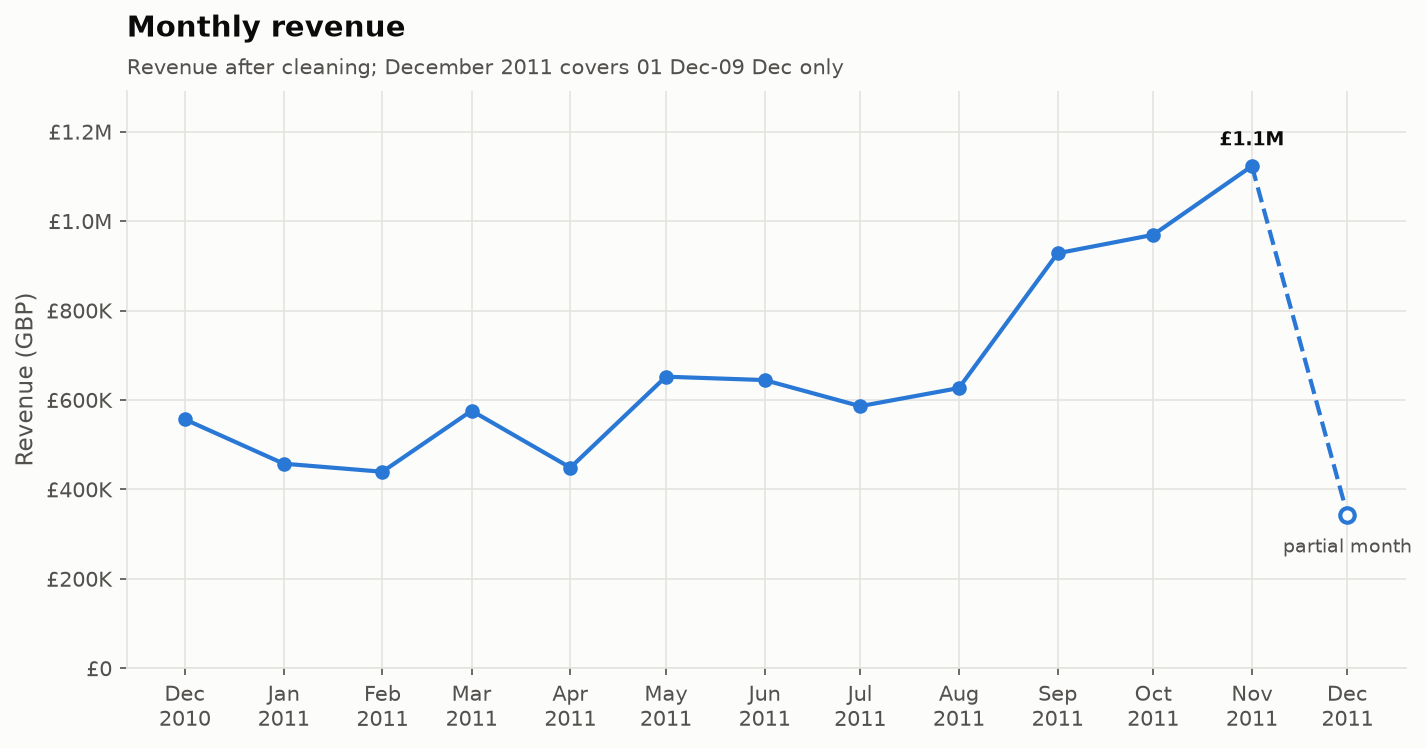

In [10]:
display(Image(FIGURES / 'monthly_revenue_trend.png'))

In [11]:
top_products(transactions, by='revenue', n=10)

,product_id,product_name,units_sold,revenue,orders,customers,revenue_share,cumulative_revenue_share,order_penetration
0,22423,REGENCY CAKESTAND 3 TIER,12033,"138,388.60",1664,873,0.02,0.02,0.09
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,34239,"94,073.65",1966,854,0.01,0.03,0.11
2,85099B,JUMBO BAG RED RETROSPOT,45197,"83,481.96",1589,633,0.01,0.04,0.09
3,47566,PARTY BUNTING,15087,"67,954.83",1369,708,0.01,0.05,0.07
4,84879,ASSORTED COLOUR BIRD ORNAMENT,35234,"56,364.02",1372,677,0.01,0.05,0.08
5,23084,RABBIT NIGHT LIGHT,27123,"51,188.84",798,449,0.01,0.06,0.04
6,22502,PICNIC BASKET WICKER SMALL,1417,"47,003.75",231,174,0.01,0.06,0.01
7,79321,CHILLI LIGHTS,9569,"45,930.36",516,204,0.01,0.07,0.03
8,22086,PAPER CHAIN KIT 50'S CHRISTMAS,15224,"41,645.48",973,611,0.00,0.07,0.05
9,21137,BLACK RECORD COVER FRAME,11389,"39,000.80",310,139,0.00,0.08,0.02


In [12]:
top_products(transactions, by='orders', n=10)

,product_id,product_name,units_sold,revenue,orders,customers,revenue_share,cumulative_revenue_share,order_penetration
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,34239,"94,073.65",1966,854,0.01,0.03,0.11
1,22423,REGENCY CAKESTAND 3 TIER,12033,"138,388.60",1664,873,0.02,0.02,0.09
2,85099B,JUMBO BAG RED RETROSPOT,45197,"83,481.96",1589,633,0.01,0.04,0.09
3,84879,ASSORTED COLOUR BIRD ORNAMENT,35234,"56,364.02",1372,677,0.01,0.05,0.08
4,47566,PARTY BUNTING,15087,"67,954.83",1369,708,0.01,0.05,0.07
5,20725,LUNCH BAG RED RETROSPOT,17354,"27,542.50",1281,530,0.00,0.13,0.07
6,22720,SET OF 3 CAKE TINS PANTRY DESIGN,6985,"33,174.55",1135,635,0.00,0.11,0.06
7,23203,JUMBO BAG VINTAGE DOILY,18857,"36,493.46",1075,504,0.00,0.09,0.06
8,20727,LUNCH BAG BLACK SKULL.,11194,"17,864.50",1047,457,0.00,0.27,0.06
9,22383,LUNCH BAG SUKI DESIGN,11576,"18,502.80",1040,433,0.00,0.26,0.06


In [13]:
order_frequency_distribution(transactions)

,orders_per_customer,customers,share_of_customers
0,1,1502,0.35
1,2,832,0.19
2,3,501,0.12
3,4,400,0.09
4,5,230,0.05
5,6,175,0.04
6,7,139,0.03
7,8,93,0.02
8,9,69,0.02
9,10+,383,0.09


In [14]:
country_performance(transactions).head(10)

,country,revenue,orders,customers,units,revenue_share,average_order_value,revenue_per_customer
0,United Kingdom,"6,877,650.53",16473,3909,4020631,0.82,417.51,"1,759.44"
1,Netherlands,"283,479.54",93,9,199934,0.03,"3,048.17","31,497.73"
2,EIRE,"247,824.82",253,3,136249,0.03,979.54,"82,608.27"
3,Germany,"203,961.43",443,94,117251,0.02,460.41,"2,169.80"
4,France,"182,143.53",377,87,109252,0.02,483.14,"2,093.60"
5,Australia,"137,124.05",53,9,83464,0.02,"2,587.25","15,236.01"
6,Switzerland,"52,093.80",46,21,29747,0.01,"1,132.47","2,480.66"
7,Spain,"52,029.97",87,29,26655,0.01,598.05,"1,794.14"
8,Japan,"37,314.37",19,8,25976,0.00,"1,963.91","4,664.30"
9,Belgium,"36,813.69",98,25,22927,0.00,375.65,"1,472.55"


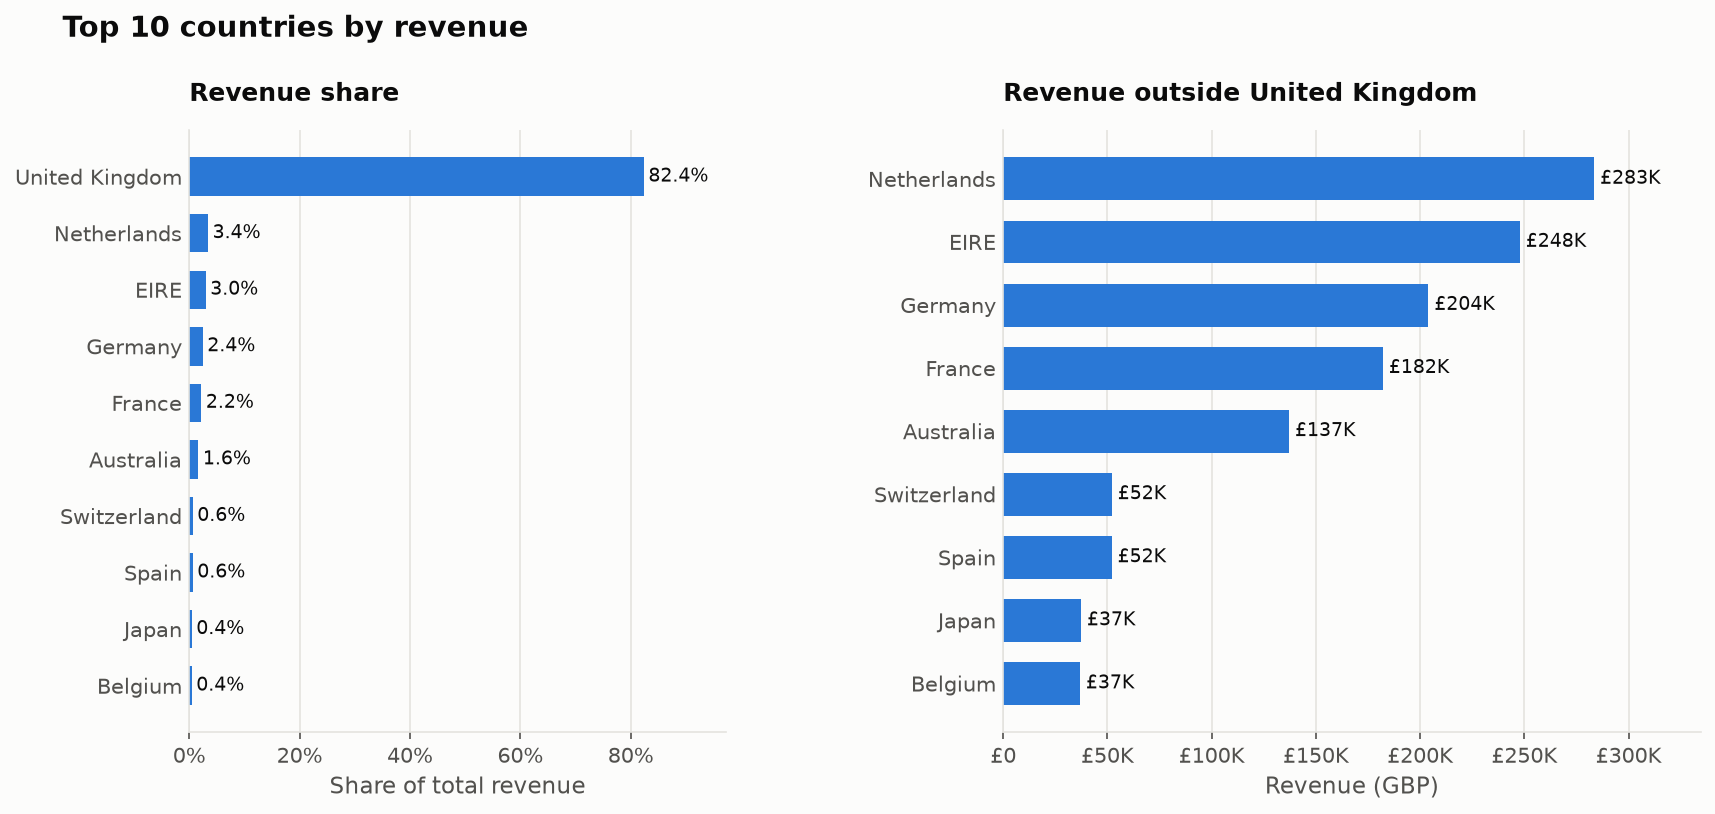

In [15]:
display(Image(FIGURES / 'country_revenue.png'))

## 3. RFM segmentation

Recency, frequency, and monetary value are scored 1-5 with tie-aware percentile ranks. Frequency and monetary scores are averaged into an FM score, and each customer is mapped to a segment from the recency x FM grid.

In [16]:
rfm = calculate_rfm(transactions)
rfm.head()

,customer_id,country,last_order_date,recency_days,frequency,monetary,r_score,f_score,m_score,fm_score,rfm_cell,rfm_total,segment
0,12347,Iceland,2011-12-07 15:52:00,3,7,"4,310.00",5,5,5,5,555,15,Champions
1,12348,Finland,2011-09-25 13:13:00,76,4,"1,437.24",2,4,4,4,244,10,At Risk
2,12349,Italy,2011-11-21 09:51:00,19,1,"1,457.55",4,1,4,3,414,9,Potential Loyalists
3,12350,Norway,2011-02-02 16:01:00,311,1,294.40,1,1,2,2,112,4,Hibernating
4,12352,Norway,2011-11-03 14:37:00,37,6,"1,265.41",3,5,4,5,354,12,Loyal Customers


In [17]:
score_thresholds(rfm)

,metric,score,min_value,max_value,customers
0,recency_days,1,180.00,374.00,871
1,recency_days,2,72.00,179.00,883
2,recency_days,3,33.00,71.00,863
3,recency_days,4,15.00,32.00,845
4,recency_days,5,1.00,13.00,862
5,frequency,1,1.00,1.00,1502
6,frequency,2,2.00,2.00,832
7,frequency,3,3.00,3.00,501
8,frequency,4,4.00,5.00,630
9,frequency,5,6.00,203.00,859


In [18]:
segment_summary(rfm)

,segment,customers,revenue,mean_recency_days,mean_frequency,mean_monetary,median_monetary,customer_share,revenue_share
0,Champions,625,"4,224,637.43",6.37,12.35,"6,759.42","2,612.96",0.14,0.51
1,Loyal Customers,793,"2,332,175.80",33.31,6.46,"2,940.95","1,838.61",0.18,0.28
2,Potential Loyalists,499,"278,478.22",16.86,2.04,558.07,480.31,0.12,0.03
3,New Customers,34,"5,299.35",7.50,1.00,155.86,158.26,0.01,0.00
4,Promising,85,"12,147.67",23.27,1.00,142.91,151.37,0.02,0.00
5,Need Attention,182,"155,627.64",51.50,2.27,855.10,713.38,0.04,0.02
6,About to Sleep,352,"104,334.43",51.70,1.24,296.40,282.81,0.08,0.01
7,Cannot Lose Them,85,"255,559.35",118.46,7.01,"3,006.58","2,615.85",0.02,0.03
8,At Risk,573,"679,643.46",151.48,2.76,"1,186.11",876.00,0.13,0.08
9,Hibernating,1096,"302,990.16",217.30,1.17,276.45,246.70,0.25,0.04


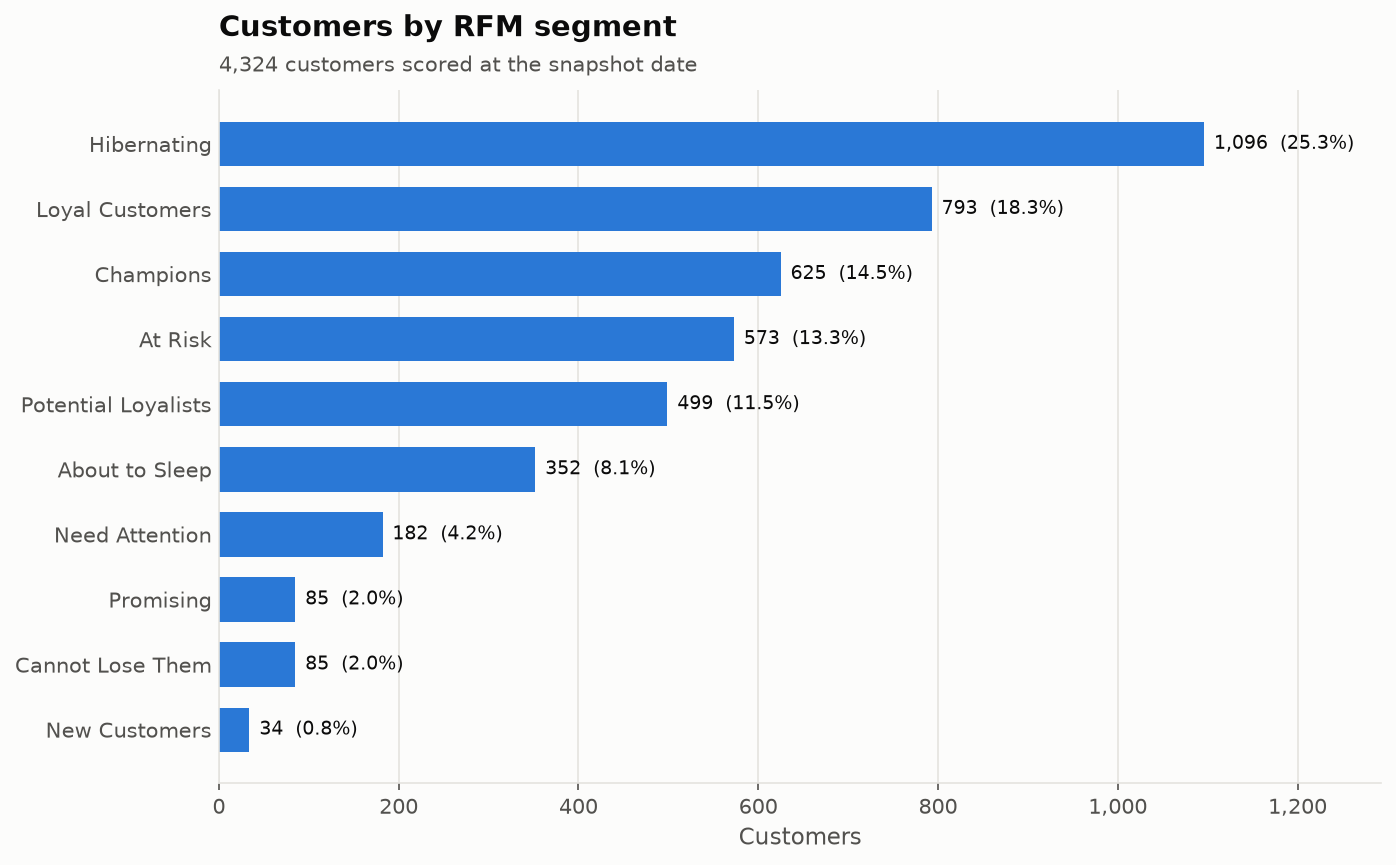

In [19]:
display(Image(FIGURES / 'customer_segment_distribution.png'))

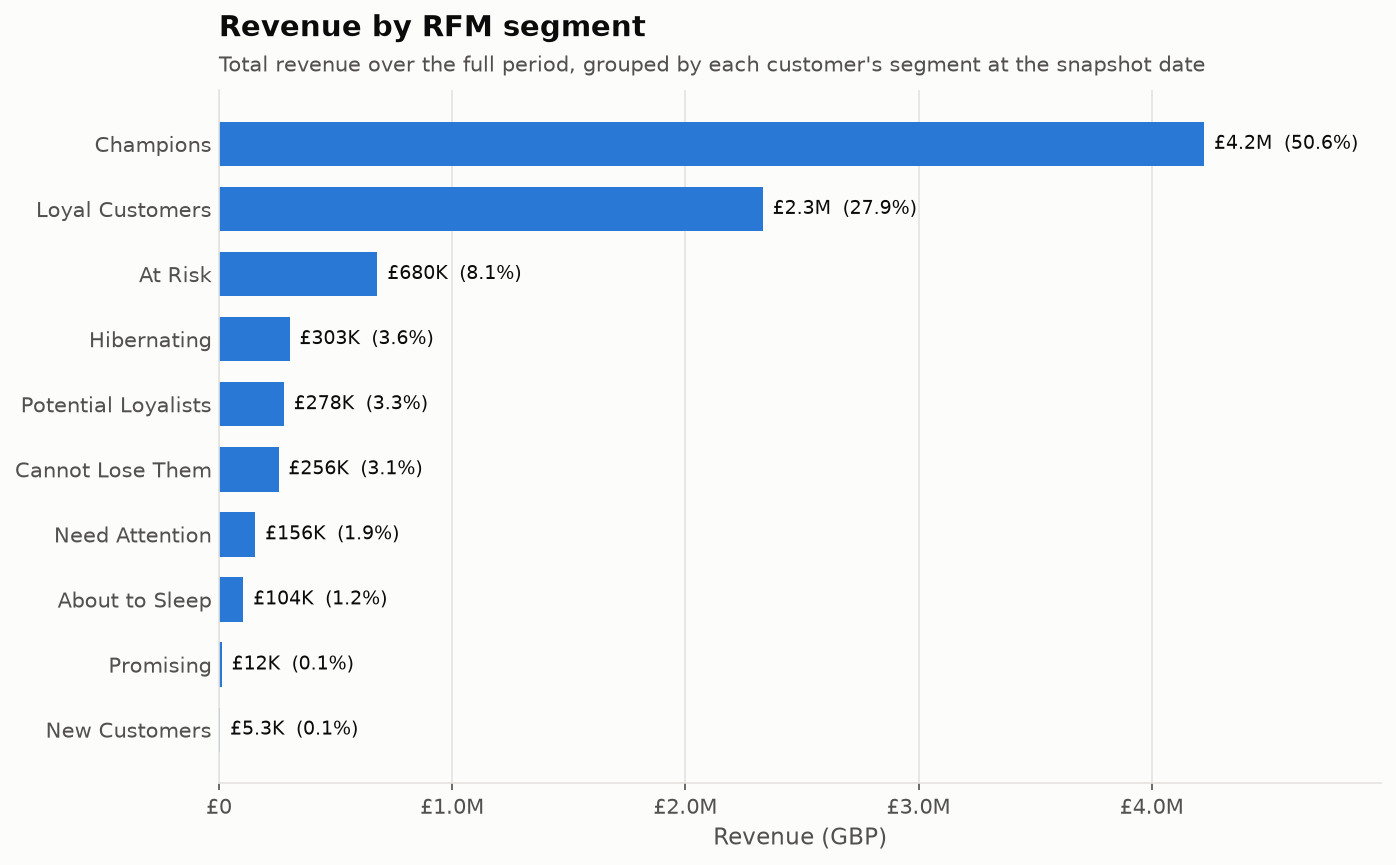

In [20]:
display(Image(FIGURES / 'revenue_by_segment.png'))

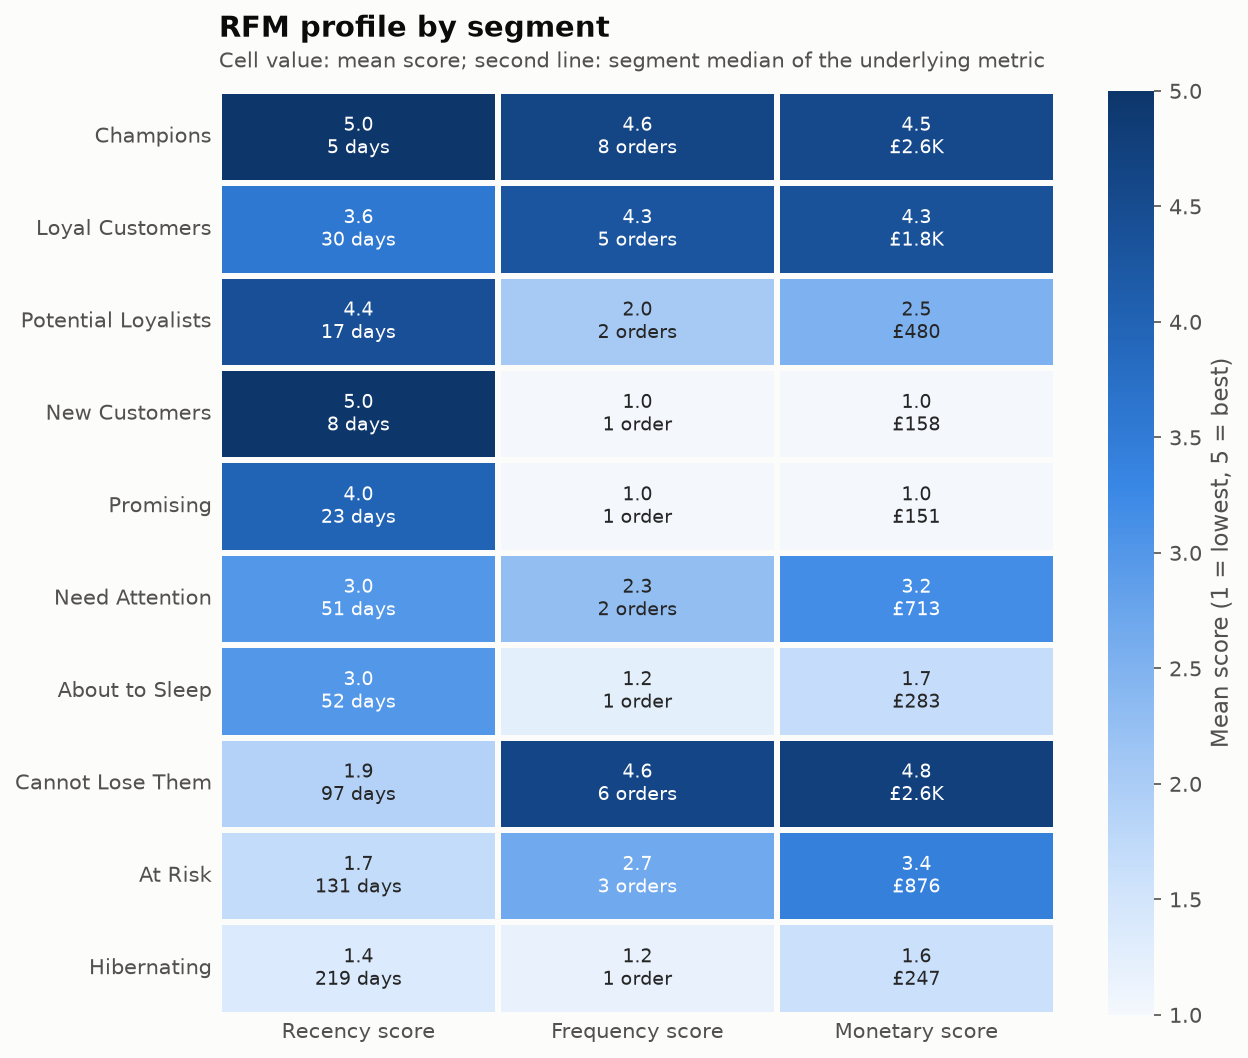

In [21]:
display(Image(FIGURES / 'rfm_segment_comparison.png'))

In [22]:
segment_activity_change(transactions, rfm)

,segment,prior_revenue,prior_active_customers,recent_revenue,recent_active_customers,revenue_change_pct
0,Champions,"874,729.90",467.00,"1,763,974.09",625,1.02
1,Loyal Customers,"574,327.08",588.00,"801,285.04",793,0.40
2,Potential Loyalists,"23,867.99",92.00,"216,079.14",499,8.05
3,New Customers,0.00,0.00,"5,299.35",34,NaN
4,Promising,0.00,0.00,"12,147.67",85,NaN
5,Need Attention,"14,377.44",49.00,"108,592.55",182,6.55
6,About to Sleep,"3,097.01",21.00,"95,652.37",352,29.89
7,Cannot Lose Them,"72,144.58",69.00,"21,875.14",35,-0.70
8,At Risk,"162,121.01",314.00,"84,487.83",141,-0.48
9,Hibernating,"72,621.64",290.00,"43,097.14",130,-0.41


## 4. Retention and repeat purchases

In [23]:
pd.Series(repeat_purchase_summary(transactions))

customers                           4,324.00
repeat_customers                    2,822.00
one_time_customers                  1,502.00
repeat_purchase_rate                    0.65
repeat_customer_revenue         7,809,843.17
repeat_customer_revenue_share           0.94
repeat_customer_order_share             0.92
dtype: float64

In [24]:
customer_type_breakdown(transactions)

,customer_type,customers,orders,revenue,mean_revenue_per_customer,median_revenue_per_customer,customer_share,revenue_share
0,One-time,1502,1502,"541,050.34",360.22,252.57,0.35,0.06
1,Returning,2822,16779,"7,809,843.17","2,767.49","1,131.42",0.65,0.94


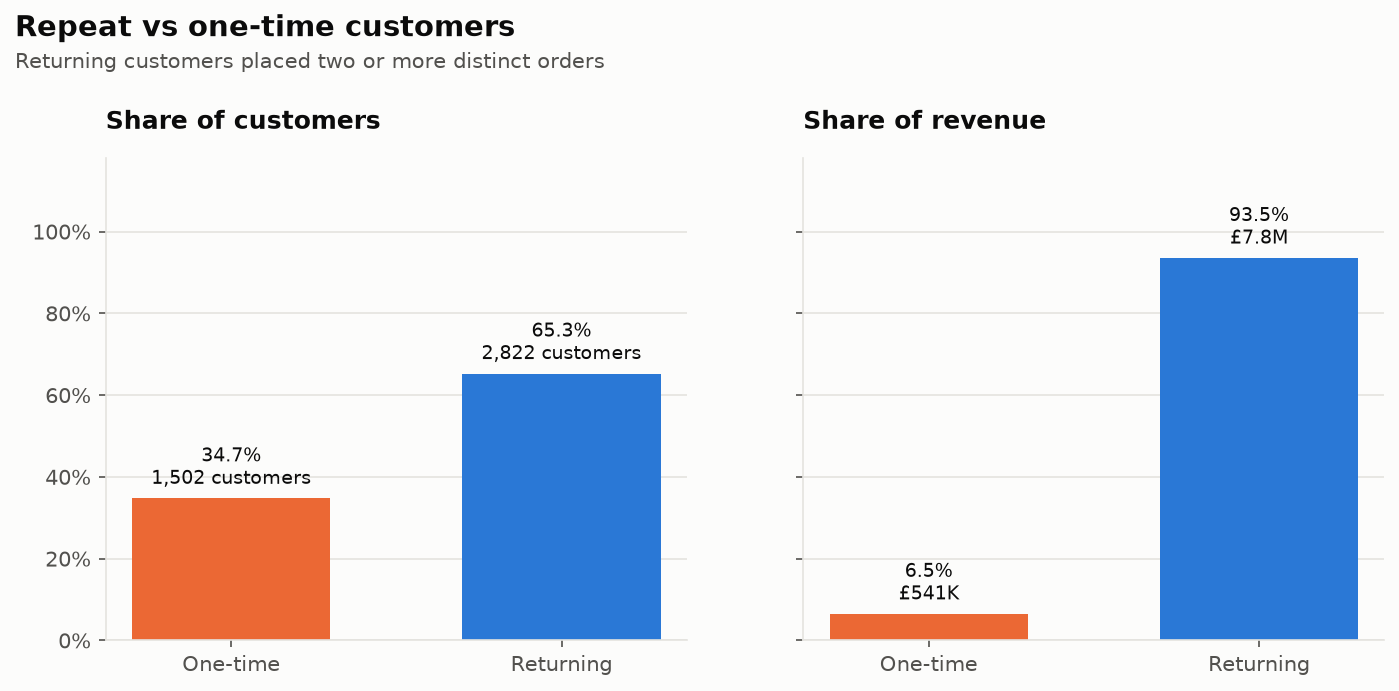

In [25]:
display(Image(FIGURES / 'repeat_vs_one_time_customers.png'))

In [26]:
days_to_second_order(transactions).describe()

count   2,822.00
mean       77.18
std        76.79
min         0.00
25%        20.00
50%        51.00
75%       112.00
max       365.00
Name: days_to_second_order, dtype: float64

In [27]:
monthly_customer_activity(transactions)

,month,active_customers,new_customers,returning_customers,new_customer_revenue,returning_customer_revenue,returning_customer_share,returning_revenue_share,cumulative_customers
0,2010-12-01,883,883,0,"556,580.13",0.00,0.00,0.00,883
1,2011-01-01,737,414,323,"188,369.62","269,133.03",0.44,0.59,1297
2,2011-02-01,756,381,375,"156,432.70","283,014.45",0.50,0.64,1678
3,2011-03-01,970,451,519,"194,853.94","381,105.01",0.54,0.66,2129
4,2011-04-01,849,300,549,"118,965.37","329,676.46",0.65,0.73,2429
5,2011-05-01,1051,283,768,"117,866.34","534,192.43",0.73,0.82,2712
6,2011-06-01,986,242,744,"131,705.29","512,789.08",0.75,0.80,2954
7,2011-07-01,945,187,758,"71,524.05","514,614.92",0.80,0.88,3141
8,2011-08-01,933,169,764,"78,181.56","548,476.06",0.82,0.88,3310
9,2011-09-01,1254,296,958,"149,838.27","778,254.64",0.76,0.84,3606


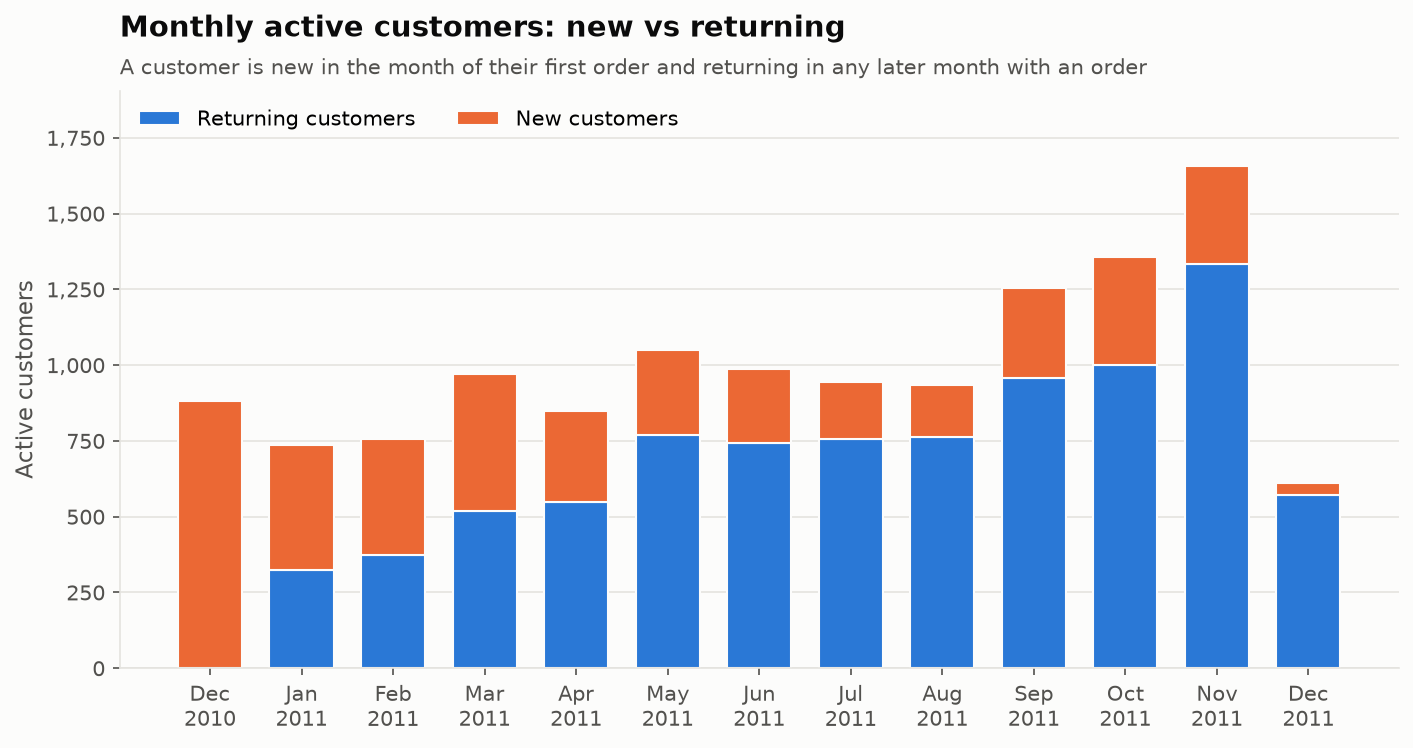

In [28]:
display(Image(FIGURES / 'monthly_new_vs_returning_customers.png'))

Cohort tables use complete months only, so the partial final month does not depress the last observable cell of every cohort.

In [29]:
coverage = month_coverage(transactions)
complete = transactions[~transactions['order_month'].isin(coverage.loc[coverage['is_partial_month'], 'month'])]
cohort_retention(complete).round(3)

months_since_acquisition,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2010-12-01,1.00,0.37,0.32,0.38,0.36,0.40,0.36,0.35,0.35,0.39,0.37,0.50
2011-01-01,1.00,0.21,0.27,0.23,0.32,0.29,0.25,0.24,0.30,0.33,0.37,NaN
2011-02-01,1.00,0.19,0.19,0.28,0.27,0.24,0.26,0.27,0.24,0.30,NaN,NaN
2011-03-01,1.00,0.15,0.25,0.20,0.22,0.17,0.27,0.23,0.28,NaN,NaN,NaN
2011-04-01,1.00,0.21,0.20,0.21,0.20,0.23,0.21,0.26,NaN,NaN,NaN,NaN
2011-05-01,1.00,0.19,0.17,0.17,0.21,0.23,0.27,NaN,NaN,NaN,NaN,NaN
2011-06-01,1.00,0.17,0.16,0.26,0.23,0.33,NaN,NaN,NaN,NaN,NaN,NaN
2011-07-01,1.00,0.18,0.20,0.23,0.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08-01,1.00,0.20,0.24,0.24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
average_retention_curve(complete)

,months_since_acquisition,retained_customers,eligible_customers,cohorts,retention_rate
0,0,"4,284.00",4284,12,1.00
1,1,931.00,3962,11,0.23
2,2,896.00,3606,10,0.25
3,3,887.00,3310,9,0.27
4,4,878.00,3141,8,0.28
5,5,854.00,2954,7,0.29
6,6,777.00,2712,6,0.29
7,7,693.00,2429,5,0.29
8,8,654.00,2129,4,0.31
9,9,598.00,1678,3,0.36


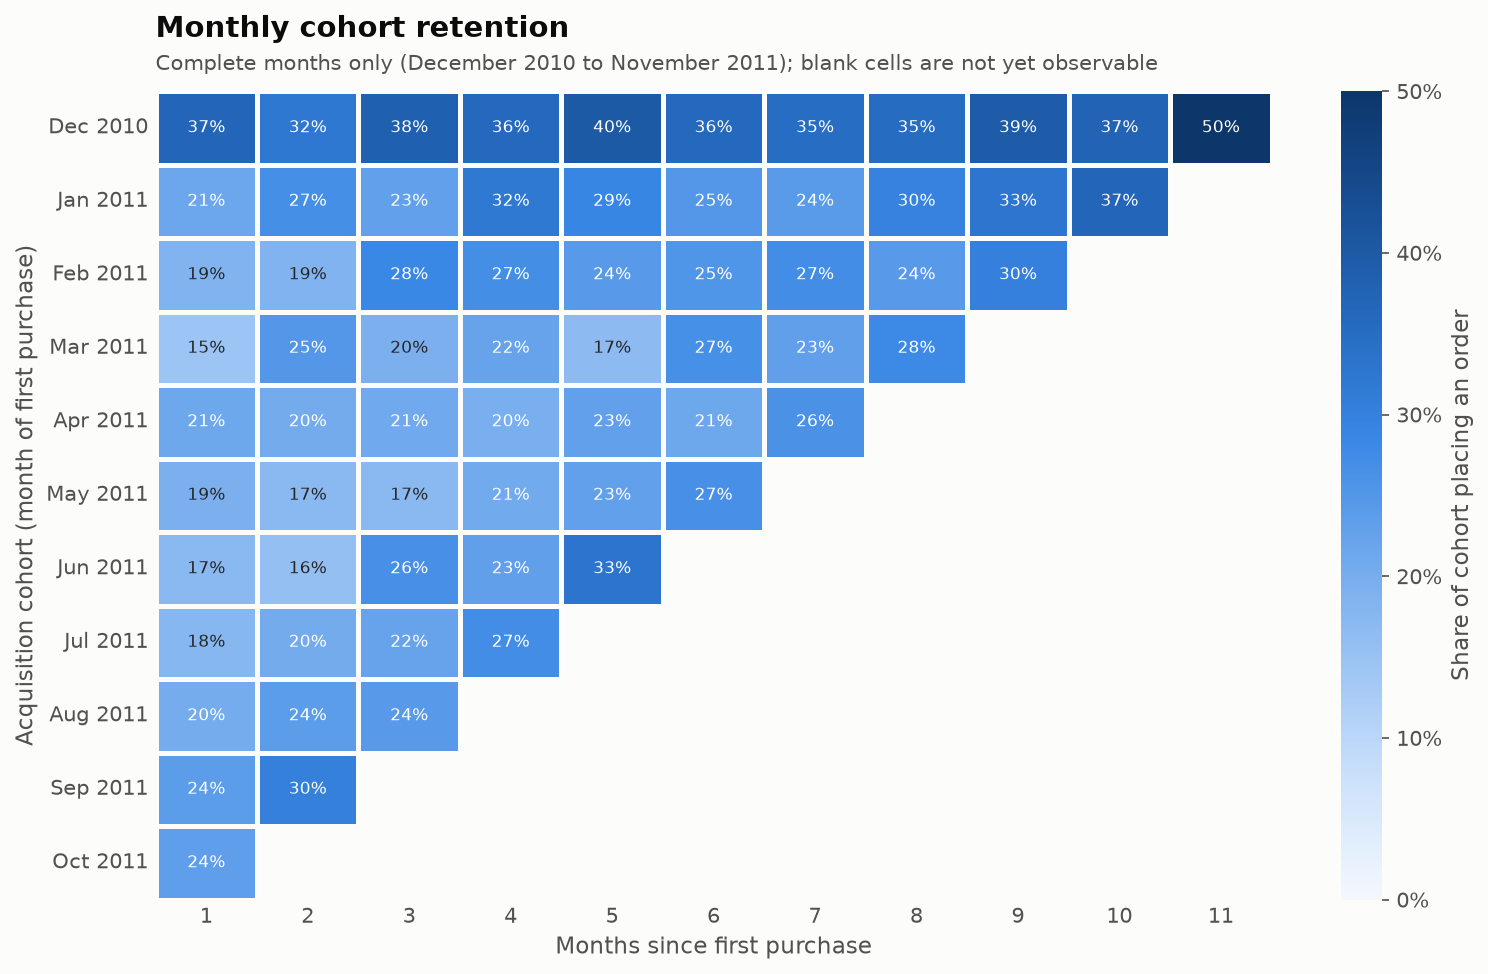

In [31]:
display(Image(FIGURES / 'cohort_retention_heatmap.png'))

In [32]:
pd.Series(lifetime_revenue_statistics(transactions))

mean       1,931.29
median       656.43
p75        1,615.79
p90        3,494.28
p99       17,329.25
max      278,778.02
dtype: float64

## 5. Revenue concentration and top customers

In [33]:
revenue_concentration(transactions)

,top_customer_share,customers,revenue,revenue_share
0,0.01,43,"2,517,462.53",0.30
1,0.05,216,"4,076,797.66",0.49
2,0.10,432,"5,022,136.14",0.60
3,0.20,865,"6,161,279.51",0.74
4,0.50,2162,"7,673,887.70",0.92


In [34]:
top_customers(transactions, n=10)

,customer_id,country,orders,revenue,revenue_share,average_order_value,first_order_date,last_order_date
0,14646,Netherlands,72,"278,778.02",0.03,"3,871.92",2010-12-20 10:09:00,2011-12-08 12:12:00
1,18102,United Kingdom,60,"259,657.30",0.03,"4,327.62",2010-12-07 16:42:00,2011-12-09 11:50:00
2,17450,United Kingdom,45,"189,607.53",0.02,"4,213.50",2010-12-07 09:23:00,2011-12-01 13:29:00
3,14911,EIRE,195,"129,667.33",0.02,664.96,2010-12-01 14:05:00,2011-12-08 15:54:00
4,12415,Australia,19,"123,806.88",0.01,"6,516.15",2011-01-06 11:12:00,2011-11-15 14:22:00
5,14156,EIRE,54,"113,866.28",0.01,"2,108.63",2010-12-03 11:48:00,2011-11-30 10:54:00
6,17511,United Kingdom,30,"88,556.38",0.01,"2,951.88",2010-12-01 10:19:00,2011-12-07 10:12:00
7,16684,United Kingdom,28,"65,920.12",0.01,"2,354.29",2010-12-16 17:34:00,2011-12-05 14:06:00
8,13694,United Kingdom,50,"63,555.30",0.01,"1,271.11",2010-12-01 12:12:00,2011-12-06 09:32:00
9,16029,United Kingdom,59,"60,369.93",0.01,"1,023.22",2010-12-01 09:57:00,2011-11-01 10:27:00


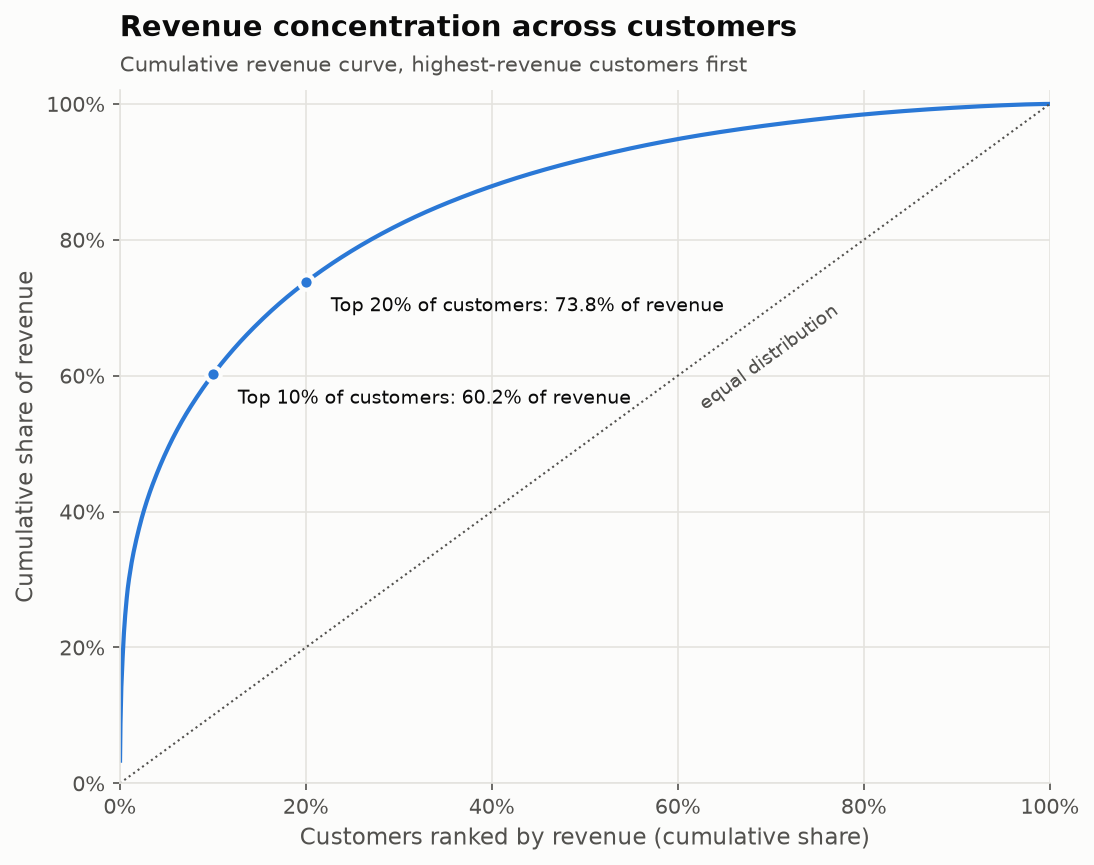

In [35]:
display(Image(FIGURES / 'revenue_concentration.png'))

## 6. SQL cross-check

The DuckDB views in `sql/` reproduce the core metrics independently of the Pandas code.

In [36]:
sql_results = run_all_sql(transactions)
sorted(sql_results)

['cohort_retention',
 'country_revenue',
 'customer_summary',
 'frequently_purchased_products',
 'monthly_customer_activity',
 'monthly_revenue',
 'orders',
 'quarterly_revenue',
 'repeat_purchase_metrics',
 'revenue_concentration',
 'rfm_scores',
 'top_customers_by_revenue',
 'top_products_by_revenue']

In [37]:
sql_results['repeat_purchase_metrics']

,customers,repeat_customers,one_time_customers,repeat_purchase_rate,repeat_customer_revenue,repeat_customer_revenue_share
0,4324,2822,1502,0.65,"7,809,843.17",0.94


In [38]:
sql_results['revenue_concentration']

,top_customer_share,customers,revenue,revenue_share
0,0.01,43,"2,517,462.53",0.30
1,0.05,216,"4,076,797.66",0.49
2,0.10,432,"5,022,136.14",0.60
3,0.20,865,"6,161,279.51",0.74
4,0.50,2162,"7,673,887.70",0.92


## 7. Findings

The written business insights and recommendations are in `reports/business_insights.md`; every number there is produced by the tables above and by `reports/summary_metrics.json`.